In [1]:

from google.colab import files

uploaded = files.upload()


Saving advertising.csv to advertising.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load the dataset
df = pd.read_csv("advertising.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:

print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Statistical summary:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000



Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows:
0

Column names:
['TV', 'Radio', 'Newspaper', 'Sales']


In [4]:

# Make a copy of the original data
df = df.copy()

# Remove duplicate rows
df = df.drop_duplicates()

# Convert all columns to numeric values
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows with missing or invalid values
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

display(df.head())


Cleaned dataset shape: (200, 4)

Missing values after cleaning:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


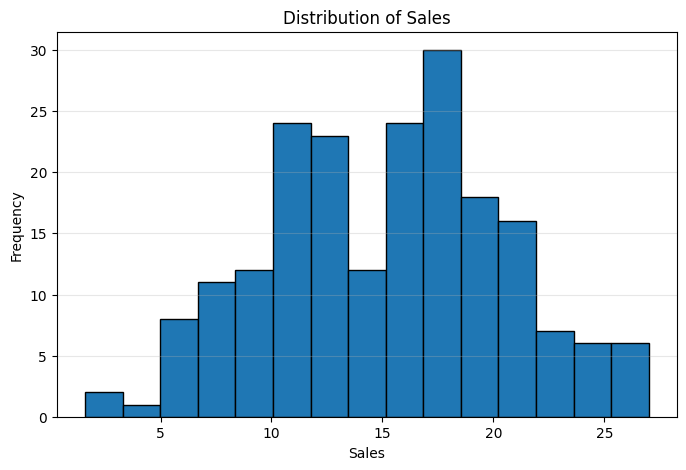

In [5]:

plt.figure(figsize=(8, 5))
plt.hist(df["Sales"], bins=15, edgecolor="black")
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()


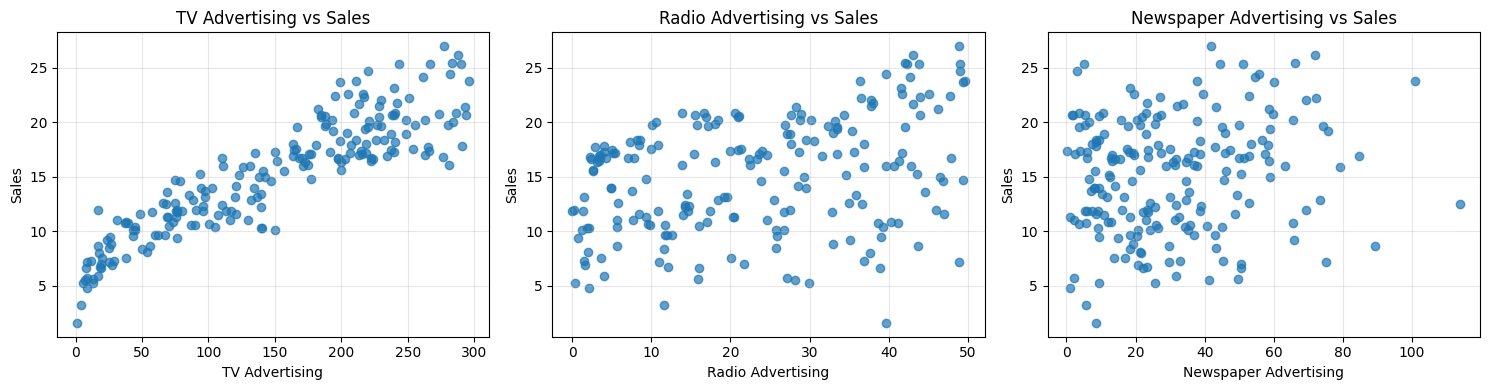

In [6]:

advertising_channels = ["TV", "Radio", "Newspaper"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, channel in zip(axes, advertising_channels):
    ax.scatter(df[channel], df["Sales"], alpha=0.7)
    ax.set_title(f"{channel} Advertising vs Sales")
    ax.set_xlabel(f"{channel} Advertising")
    ax.set_ylabel("Sales")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


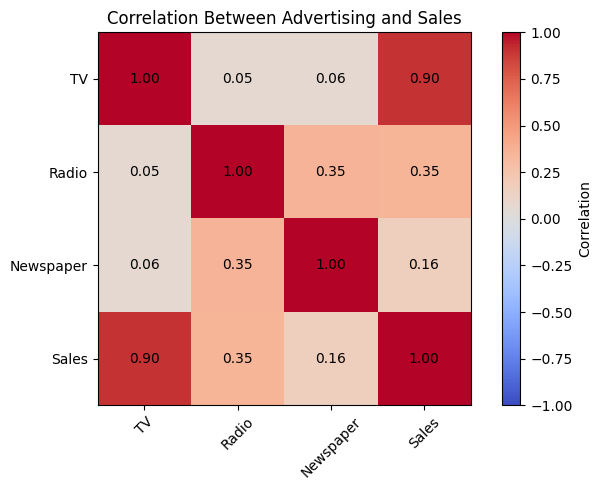

In [7]:

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(7, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)),
           correlation.columns)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Between Advertising and Sales")
plt.tight_layout()
plt.show()


In [8]:

# Input features
X = df[["TV", "Radio", "Newspaper"]]

# Target variable
y = df["Sales"]

print("Input features:", X.columns.tolist())
print("Target variable: Sales")
print("Total samples:", len(df))


Input features: ['TV', 'Radio', 'Newspaper']
Target variable: Sales
Total samples: 200


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 160
Testing samples: 40


In [10]:

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

print("\nModel coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

print("\nIntercept:", round(model.intercept_, 4))


Linear Regression model trained successfully!

Model coefficients:
TV: 0.0545
Radio: 0.1009
Newspaper: 0.0043

Intercept: 4.7141


In [11]:

# Predict sales on the test data
y_pred = model.predict(X_test)

# Display actual and predicted sales
results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

results["Absolute Error"] = (
    results["Actual Sales"] - results["Predicted Sales"]
).abs()

display(results.head(10).round(3))


,Actual Sales,Predicted Sales,Absolute Error
0,16.9,17.035,0.135
1,22.4,20.410,1.990
2,21.4,23.724,2.324
3,7.3,9.273,1.973
4,24.7,21.683,3.017
5,12.6,12.569,0.031
6,22.3,21.081,1.219
7,8.4,8.690,0.290
8,16.5,17.237,0.737
9,16.1,16.667,0.567


In [12]:

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("=" * 40)
print("MODEL EVALUATION")
print("=" * 40)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")


MODEL EVALUATION
Mean Absolute Error (MAE): 1.2748
Root Mean Squared Error (RMSE): 1.7052
R-squared (R2): 0.9059


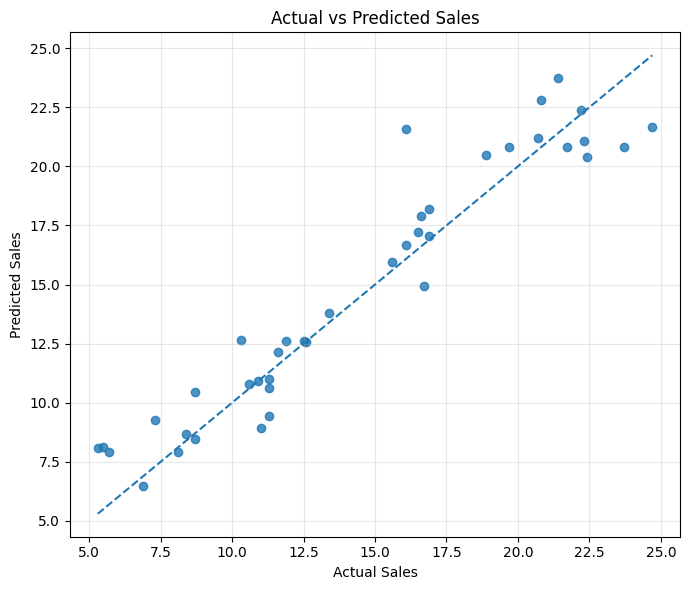

In [13]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.8)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:

# Example advertising budget
new_advertising = pd.DataFrame({
    "TV": [200.0],
    "Radio": [35.0],
    "Newspaper": [40.0]
})

predicted_sales = model.predict(new_advertising)

print("New advertising budget:")
display(new_advertising)

print(
    f"Predicted sales: {predicted_sales[0]:.2f}"
)


New advertising budget:


,TV,Radio,Newspaper
0,200.0,35.0,40.0


Predicted sales: 19.32


In [15]:

import joblib

# Save trained model
joblib.dump(model, "sales_prediction_model.pkl")

# Save actual and predicted values
results.to_csv("sales_prediction_results.csv", index=False)

# Save evaluation metrics
metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2]
})

metrics_df.to_csv("sales_prediction_metrics.csv", index=False)

print("Model, predictions, and metrics saved successfully!")


Model, predictions, and metrics saved successfully!


In [16]:

files.download("sales_prediction_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

files.download("sales_prediction_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

files.download("sales_prediction_metrics.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>